In [1]:
import numpy as np, math, matplotlib.pyplot as plt

In [2]:
#Initialize Vars
g = -32
vel_0 = 98
ang_initial = 62
y_initial = 34

ang_rad = math.radians(ang_initial) 

#Array Setup
time = np.linspace(0 , 20, 1000)
velx_0 = vel_0 * math.cos(ang_rad)
vely_0 = vel_0 * math.sin(ang_rad)


def parametric(parameter, position, velocity, acceleration):
    positions = (0.5 * acceleration * parameter ** 2) + (velocity * parameter) + position
    return positions

x_coords = parametric(time, 0, velx_0, 0)
y_coords = parametric(time, y_initial, vely_0, g)
y_coords = y_coords



In [3]:
#Get Solutions Function
def find_solutions(t, x, y):
    ground_intersect = y <= 0 
    if t[ground_intersect][0] > 0:
        impact = t[ground_intersect][0]
    else:
        impact = t[ground_intersect][1]
    if x[ground_intersect][0] > 0:
        delta_x = x[ground_intersect][0]
    else:
        delta_x = x[ground_intersect][1]
    peak = y[np.argmax(y)]
    return impact, delta_x, peak




Flight time: 5.79; Distance Traveled: 266.19; Peak Height: 150.99; Peak Time: 2.895


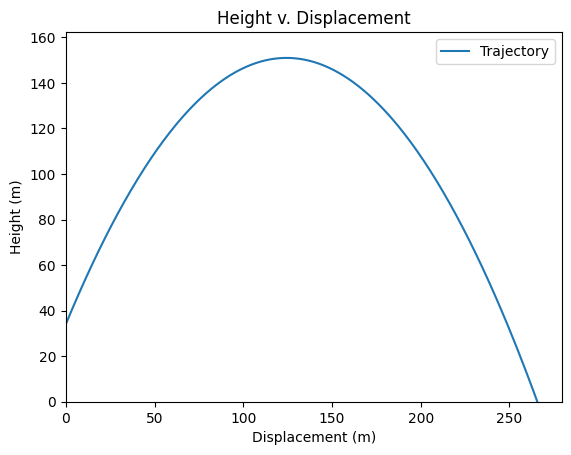

In [4]:
#Plot Data

def title_graph(title, x_label, y_label):
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel(y_label)

def solve(title, line_label, x_label, y_label, t, x, y):
   
    plt.figure()
    title_graph(title, x_label, y_label)
    plt.plot(x, y, label = line_label)
    plt.legend()
    
    
    #Limits

    impact_time, displacement,  y_max = find_solutions(t, x , y)
    plt.ylim(0, y_max + .075 * y_max )
    plt.xlim(0, displacement + 0.05 * displacement) 

    #Give Solutions
    return impact_time, displacement,  y_max

#Draw Graphs

solutions = solve('Height v. Displacement', 'Trajectory', 'Displacement (m)', 'Height (m)', time, x_coords, y_coords)
time_solution, dis_trav, height_max = solutions

#Round and Anunciate Solutions
time_solution = round(time_solution, 2)
dis_trav = round(dis_trav, 2)
height_max = round(height_max, 2)

print(f'Flight time: {time_solution}; Distance Traveled: {dis_trav}; Peak Height: {height_max}; Peak Time: {time_solution / 2}')